In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings("ignore")

In [2]:

H, MIN_TRAIN, STEP, M = 3, 24, 1, 12

In [3]:
df = pd.read_excel("MAIZE DATA NOW.xlsx")

df = df.rename(columns={"Average Price": "price", "Date": "date"})

df["date"] = pd.to_datetime(df["date"])

df.head()


,price,date
0,197.130429,2023-01-01
1,187.067148,2023-02-01
2,189.972943,2023-03-01
3,213.582186,2023-04-01
4,243.822625,2023-05-01


In [4]:
y = df.set_index("date")["price"].sort_index().asfreq("MS")
ly = np.log(y)
print(f"{len(y)} months: {y.index[0]:%b %Y} to {y.index[-1]:%b %Y}; missing={y.isna().sum()}")

46 months: Jan 2023 to Oct 2026; missing=0


In [5]:
def adf(s, name):
    stat, p = adfuller(s.dropna(), autolag="AIC")[:2]
    print(f"ADF {name:<22} stat={stat:7.3f}  p={p:.4f}  -> {'stationary' if p < 0.05 else 'NON-stationary'}")

adf(ly, "log price")
adf(ly.diff(), "diff(1)")



ADF log price              stat= -2.270  p=0.1818  -> NON-stationary
ADF diff(1)                stat= -4.267  p=0.0005  -> stationary


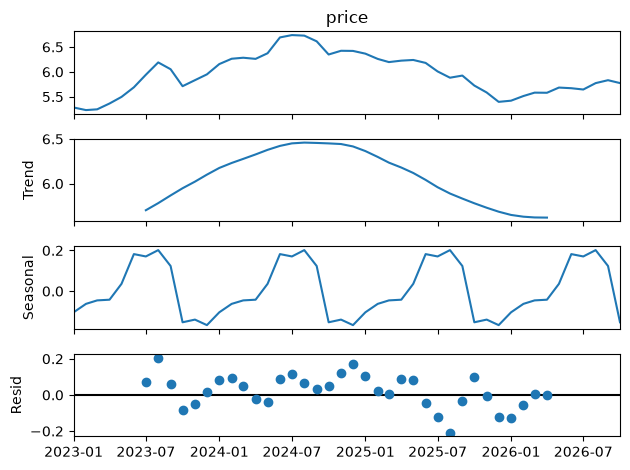

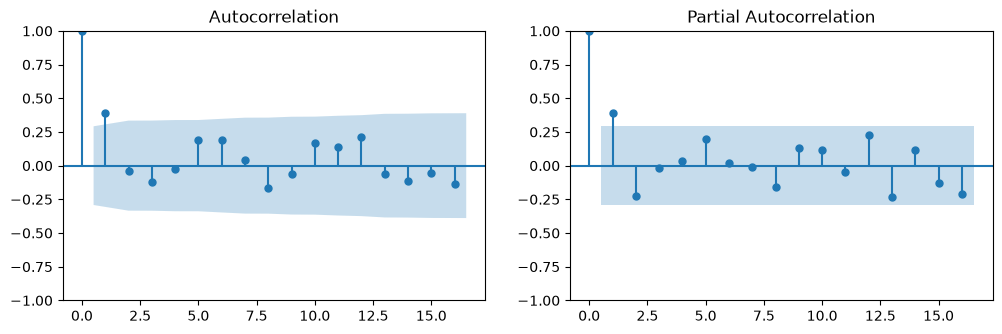

In [19]:
seasonal_decompose(ly, model="additive", period=M).plot()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(ly.diff().dropna(), lags=16, ax=ax[0]);  plot_pacf(ly.diff().dropna(), lags=16, ax=ax[1], method="ywm")
plt.show()

In [6]:


cands = {
    "(1,1,0)(0,0,0)": ((1,1,0), (0,0,0,M)),
    "(0,1,1)(0,0,0)": ((0,1,1), (0,0,0,M)),
    "(1,1,1)(0,0,0)": ((1,1,1), (0,0,0,M)),
    "(1,1,0)(1,0,0)": ((1,1,0), (1,0,0,M)),
    "(0,1,1)(0,0,1)": ((0,1,1), (0,0,1,M)),
}

for name, (order, sorder) in cands.items():
    res = SARIMAX(ly, order=order, seasonal_order=sorder).fit(disp=False)
    lb = acorr_ljungbox(res.resid[1:], lags=[12], return_df=True)["lb_pvalue"].iloc[0]
    print(f"{name:18} AIC={res.aic:8.2f}  BIC={res.bic:8.2f}  LjungBox p={lb:.3f}")

(1,1,0)(0,0,0)     AIC=  -55.39  BIC=  -51.78  LjungBox p=0.202
(0,1,1)(0,0,0)     AIC=  -57.26  BIC=  -53.65  LjungBox p=0.331
(1,1,1)(0,0,0)     AIC=  -55.29  BIC=  -49.87  LjungBox p=0.322
(1,1,0)(1,0,0)     AIC=  -57.57  BIC=  -52.15  LjungBox p=0.082
(0,1,1)(0,0,1)     AIC=  -60.72  BIC=  -55.30  LjungBox p=0.590


                               SARIMAX Results                                
Dep. Variable:                  price   No. Observations:                   46
Model:               SARIMAX(0, 1, 1)   Log Likelihood                  30.632
Date:                Mon, 02 Nov 2026   AIC                            -57.264
Time:                        15:39:56   BIC                            -53.650
Sample:                    01-01-2023   HQIC                           -55.917
                         - 10-01-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1          0.4730      0.134      3.520      0.000       0.210       0.736
sigma2         0.0149      0.004      4.063      0.000       0.008       0.022
Ljung-Box (L1) (Q):                   0.01   Jarque-

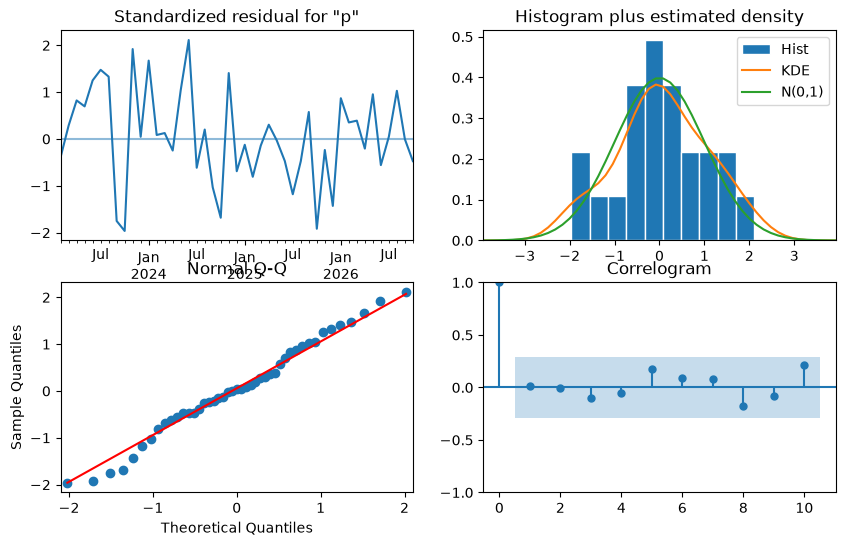

In [16]:
best = SARIMAX(ly, order=(0,1,1), seasonal_order=(0,0,0,M)).fit(disp=False)
print(best.summary())
best.plot_diagnostics(figsize=(10,6))
plt.show()

            actual  forecast  lower_95  upper_95  error_%
2026-08-01  321.69    283.48    222.04    361.91   -11.88
2026-09-01  341.19    283.48    183.98    436.77   -16.91
2026-10-01  321.95    283.48    161.86    496.48   -11.95


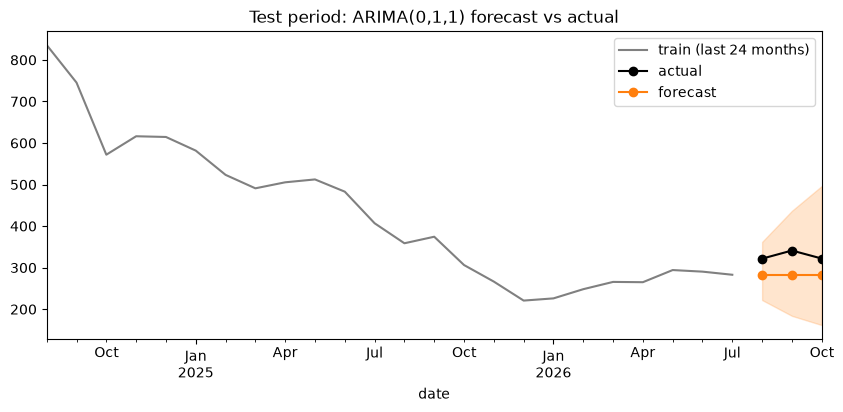

In [7]:
order, sorder = (0,1,1), (0,0,0,M)


train, test = ly.iloc[:-H], ly.iloc[-H:]
r_tr = SARIMAX(train, order=order, seasonal_order=sorder).fit(disp=False)
fc_t = r_tr.get_forecast(H)
ci_t = np.exp(fc_t.conf_int())

cmp = pd.DataFrame({
    "actual":   np.exp(test),
    "forecast": np.exp(fc_t.predicted_mean),
    "lower_95": ci_t.iloc[:, 0],
    "upper_95": ci_t.iloc[:, 1],
})
cmp["error_%"] = (cmp["forecast"] - cmp["actual"]) / cmp["actual"] * 100
print(cmp.round(2))

fig, ax = plt.subplots(figsize=(10, 4))
np.exp(train).iloc[-24:].plot(ax=ax, color="gray", label="train (last 24 months)")
cmp["actual"].plot(ax=ax, color="black", marker="o", label="actual")
cmp["forecast"].plot(ax=ax, color="C1", marker="o", label="forecast")
ax.fill_between(cmp.index, cmp["lower_95"], cmp["upper_95"], color="C1", alpha=0.2)
ax.set_title("Test period: ARIMA(0,1,1) forecast vs actual")
ax.legend(); plt.show()

            forecast  lower_95  upper_95
2026-11-01    313.27    246.57    398.01
2026-12-01    313.27    204.55    479.77
2027-01-01    313.27    180.16    544.73


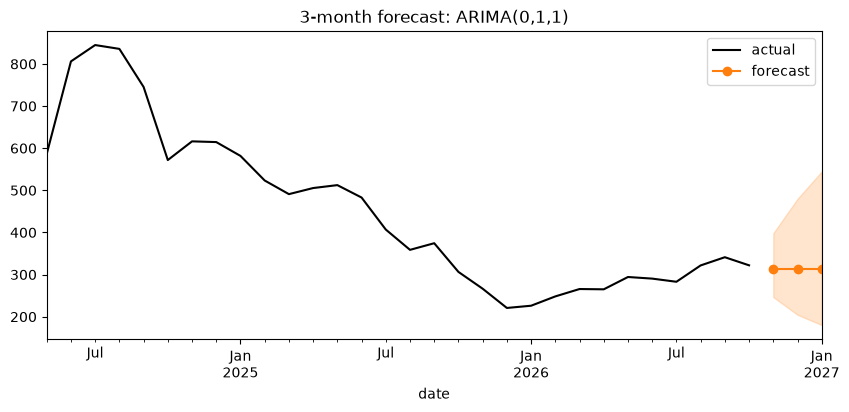

In [18]:
final = SARIMAX(ly, order=order, seasonal_order=sorder).fit(disp=False)
fc = final.get_forecast(H)
ci = np.exp(fc.conf_int())

future = pd.DataFrame({
    "forecast": np.exp(fc.predicted_mean),
    "lower_95": ci.iloc[:, 0],
    "upper_95": ci.iloc[:, 1],
})
print(future.round(2))

fig, ax = plt.subplots(figsize=(10, 4))
np.exp(ly).iloc[-30:].plot(ax=ax, color="black", label="actual")
future["forecast"].plot(ax=ax, color="C1", marker="o", label="forecast")
ax.fill_between(future.index, future["lower_95"], future["upper_95"], color="C1", alpha=0.2)
ax.set_title("3-month forecast: ARIMA(0,1,1)")
ax.legend(); plt.show()

            forecast  lower_95  upper_95
2026-11-01    313.27    246.57    398.01
2026-12-01    313.27    204.55    479.77
2027-01-01    313.27    180.16    544.73


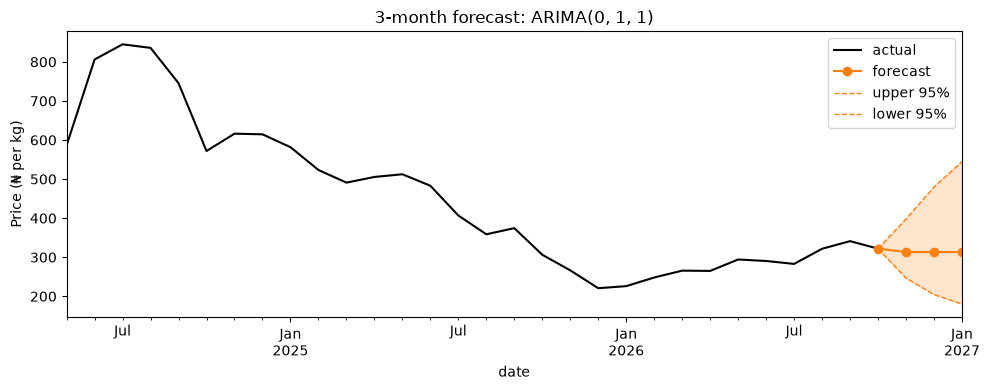

In [8]:
final = SARIMAX(ly, order=order, seasonal_order=sorder).fit(disp=False)
fc = final.get_forecast(H)
ci = np.exp(fc.conf_int())

future = pd.DataFrame({
    "forecast": np.exp(fc.predicted_mean),
    "lower_95": ci.iloc[:, 0],
    "upper_95": ci.iloc[:, 1],
})
print(future.round(2))

# Anchor the forecast to the last actual point so there is no gap
actual = np.exp(ly).iloc[-30:]
last_date, last_val = actual.index[-1], actual.iloc[-1]

def anchor(s):
    return pd.concat([pd.Series([last_val], index=[last_date]), s])

fc_line = anchor(future["forecast"])
lo_line = anchor(future["lower_95"])
hi_line = anchor(future["upper_95"])

fig, ax = plt.subplots(figsize=(10, 4))
actual.plot(ax=ax, color="black", label="actual")
fc_line.plot(ax=ax, color="C1", marker="o", label="forecast")
hi_line.plot(ax=ax, color="C1", linestyle="--", linewidth=1, label="upper 95%")
lo_line.plot(ax=ax, color="C1", linestyle="--", linewidth=1, label="lower 95%")
ax.fill_between(fc_line.index, lo_line, hi_line, color="C1", alpha=0.2)

ax.set_title(f"3-month forecast: ARIMA{order}")
ax.set_ylabel("Price (₦ per kg)")
ax.margins(x=0.05)
ax.legend()
plt.tight_layout()
plt.show()

In [18]:
from statsmodels.tsa.forecasting.stl import STLForecast
from statsmodels.tsa.arima.model import ARIMA

dd = pd.read_excel("MAIZE OPEN MARKET.xlsx").rename(
    columns={"market date": "date", "National Aerage": "price"})

# dates are text like "01/01/2023 00:00" (dd/mm/yyyy), so parse explicitly
dd["date"] = pd.to_datetime(dd["date"].astype(str).str.strip(),
                            format="%d/%m/%Y %H:%M", errors="coerce")
dd["price"] = pd.to_numeric(dd["price"], errors="coerce")
print("unparsed dates:", dd["date"].isna().sum(), "| bad prices:", dd["price"].isna().sum())
dd = dd.dropna(subset=["date", "price"]).drop_duplicates("date")

yd = dd.set_index("date")["price"].sort_index().asfreq("D")
print(yd.index.min().date(), "to", yd.index.max().date(), "| missing days:", yd.isna().sum())

# ---- gap check: lengths and locations of missing stretches ----
miss = yd.isna()
gid = (miss != miss.shift()).cumsum()
gaps = (miss.groupby(gid).agg(["first", "size"])
        .join(yd.index.to_series().groupby(gid).agg(start="min", end="max")))
gaps = gaps[gaps["first"]].rename(columns={"size": "days"}).sort_values("days", ascending=False)
print("number of gaps:", len(gaps))
print(gaps[["start", "end", "days"]].head(5).to_string(index=False))
assert gaps["days"].max() <= 14, "a gap longer than 14 days exists, see table above"

lyd = np.log(yd.interpolate("time"))

HD, MIN_D, STEP_D = 30, 730, 45     # 30-day horizon, 2 yrs min train, new origin every 45 days

def f_naive(tr):  return np.repeat(tr.iloc[-1], HD)
def f_arima(tr):  return SARIMAX(tr, order=(0,1,1)).fit(disp=False).forecast(HD).values
def f_stlm7(tr):  return STLForecast(tr, ARIMA, model_kwargs=dict(order=(0,1,1)),
                                     period=7, robust=True).fit().forecast(HD).values

models = {"naive": f_naive, "ARIMA(0,1,1)": f_arima, "STLM weekly": f_stlm7}
ape = {k: [] for k in models}
for t in range(MIN_D, len(lyd) - HD + 1, STEP_D):
    tr, te = lyd.iloc[:t], lyd.iloc[t:t+HD]
    a = np.exp(te.values)
    for k, fn in models.items():
        ape[k].append(np.abs(np.exp(fn(tr)) - a) / a * 100)

print(pd.Series({k: np.mean(v) for k, v in ape.items()}).round(2))
print(pd.DataFrame({k: np.mean(v, axis=0)[[0,6,13,29]] for k, v in ape.items()},
                   index=["h=1","h=7","h=14","h=30"]).T.round(2))

unparsed dates: 0 | bad prices: 0
2023-01-01 to 2026-10-31 | missing days: 156
number of gaps: 78
     start        end  days
2026-09-11 2026-09-16     6
2026-07-25 2026-07-29     5
2026-08-29 2026-09-02     5
2026-07-11 2026-07-15     5
2026-09-19 2026-09-23     5
naive           7.65
ARIMA(0,1,1)    7.70
STLM weekly     7.23
dtype: float64
               h=1   h=7  h=14   h=30
naive         2.71  4.70  6.50  11.74
ARIMA(0,1,1)  2.75  4.91  6.23  12.18
STLM weekly   3.13  4.90  6.30  10.73


test window: 2026-08-03 to 2026-10-31
              MAPE_%  bias_%  inside_95%_band
naive           9.13   -6.93              NaN
ARIMA(0,1,1)   10.13   -8.46           100.00
STLM weekly    12.12  -11.34            95.56


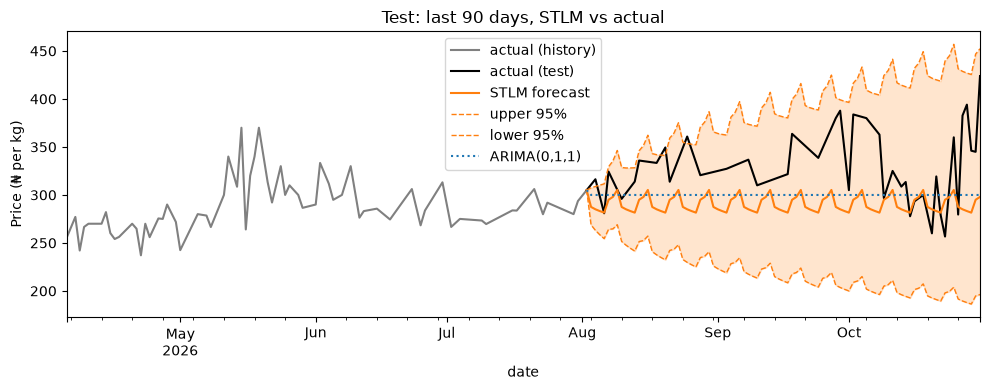

forecast window: 2026-11-01 to 2027-01-29
            forecast  lower_95  upper_95
2026-11-01    360.74    335.12    388.31
2026-11-30    340.07    263.29    439.26
2026-12-30    418.83    293.00    598.68
2027-01-29    348.55    225.46    538.84


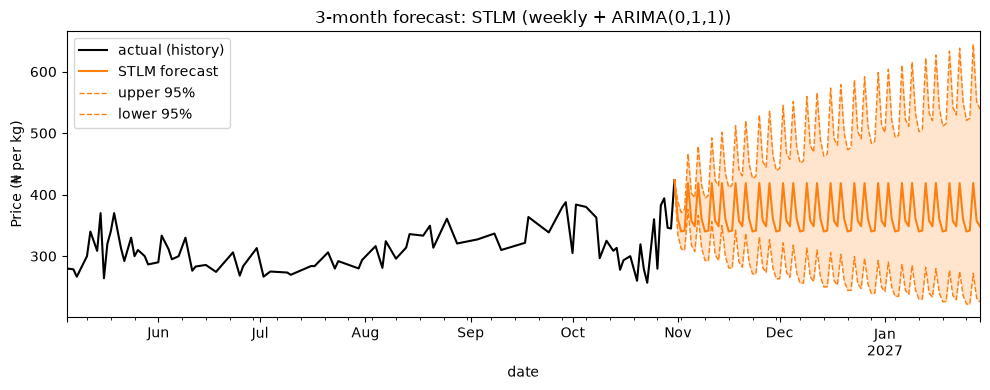

In [20]:
from statsmodels.tsa.forecasting.stl import STLForecast
from statsmodels.tsa.arima.model import ARIMA

HF = 90   # 3-month horizon

def _frame(pred):
    ci = np.exp(pred.conf_int())
    return pd.DataFrame({"forecast": np.exp(pred.predicted_mean),
                         "lower_95": ci.iloc[:, 0], "upper_95": ci.iloc[:, 1]})

def fc_stlm(tr, h=HF):
    res = STLForecast(tr, ARIMA, model_kwargs=dict(order=(0,1,1)),
                      period=7, robust=True).fit()
    return _frame(res.get_prediction(start=len(tr), end=len(tr) + h - 1))

def fc_arima(tr, h=HF):
    return _frame(SARIMAX(tr, order=(0,1,1)).fit(disp=False).get_forecast(h))

def fc_naive(tr, h=HF):
    idx = pd.date_range(tr.index[-1] + pd.Timedelta(days=1), periods=h, freq="D")
    return pd.DataFrame({"forecast": np.exp(tr.iloc[-1])}, index=idx)

def plot_fc(hist, fc, title, test=None, extra=None):
    last_date, last_val = hist.index[-1], hist.iloc[-1]
    anchor = lambda s: pd.concat([pd.Series([last_val], index=[last_date]), s])
    fig, ax = plt.subplots(figsize=(10, 4))
    hist.plot(ax=ax, color="gray" if test is not None else "black", label="actual (history)")
    if test is not None:
        pd.concat([hist.iloc[[-1]], test]).plot(ax=ax, color="black", label="actual (test)")
    f, lo, hi = (anchor(fc[c]) for c in ["forecast", "lower_95", "upper_95"])
    f.plot(ax=ax, color="C1", label="STLM forecast")
    hi.plot(ax=ax, color="C1", ls="--", lw=1, label="upper 95%")
    lo.plot(ax=ax, color="C1", ls="--", lw=1, label="lower 95%")
    ax.fill_between(f.index, lo, hi, color="C1", alpha=0.2)
    if extra is not None:
        anchor(extra["forecast"]).plot(ax=ax, color="C0", ls=":", label="ARIMA(0,1,1)")
    ax.set_title(title); ax.set_ylabel("Price (₦ per kg)"); ax.margins(x=0.02)
    ax.legend(); plt.tight_layout(); plt.show()

# ---------- 1) Test: hold out the last 90 days ----------
train, test = lyd.iloc[:-HF], lyd.iloc[-HF:]
act = np.exp(test)
print(f"test window: {test.index[0].date()} to {test.index[-1].date()}")

rows = {}
for name, fn in {"naive": fc_naive, "ARIMA(0,1,1)": fc_arima, "STLM weekly": fc_stlm}.items():
    f = fn(train)
    err = (f["forecast"] - act) / act * 100
    row = {"MAPE_%": err.abs().mean(), "bias_%": err.mean()}
    if "lower_95" in f:
        row["inside_95%_band"] = ((act >= f["lower_95"]) & (act <= f["upper_95"])).mean() * 100
    rows[name] = row
print(pd.DataFrame(rows).T.round(2))

t_st, t_ar = fc_stlm(train), fc_arima(train)
plot_fc(np.exp(train).iloc[-120:], t_st, "Test: last 90 days, STLM vs actual", test=act, extra=t_ar)

# ---------- 2) Final: next 3 months ----------
future = fc_stlm(lyd)
print(f"forecast window: {future.index[0].date()} to {future.index[-1].date()}")
print(future.iloc[[0, 29, 59, 89]].round(2))          # day 1, 30, 60, 90
plot_fc(np.exp(lyd).iloc[-180:], future, "3-month forecast: STLM (weekly + ARIMA(0,1,1))")

              MAPE_%  bias_%  inside_95%_band
naive           7.41   -6.48              NaN
ARIMA(0,1,1)    8.64   -8.09            98.89
STLM weekly    11.96  -10.34            91.11


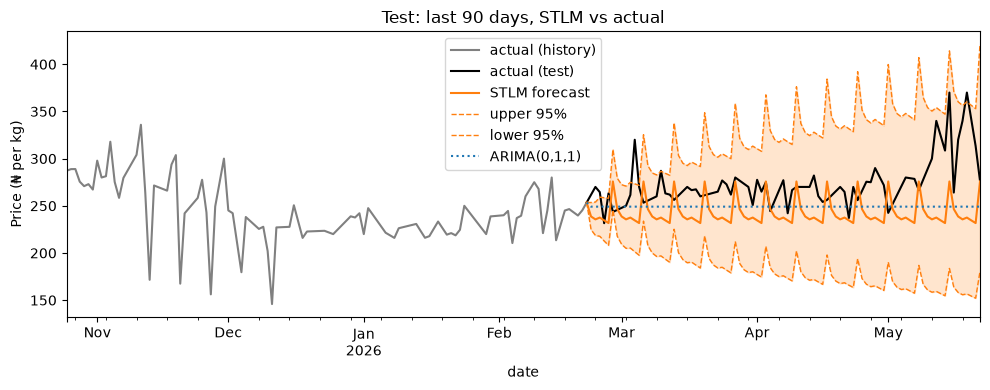

            forecast  lower_95  upper_95
2026-05-23    263.73    246.72    281.91
2026-06-21    317.57    248.27    406.20
2026-07-21    360.63    255.53    508.97
2026-08-20    300.65    197.45    457.79


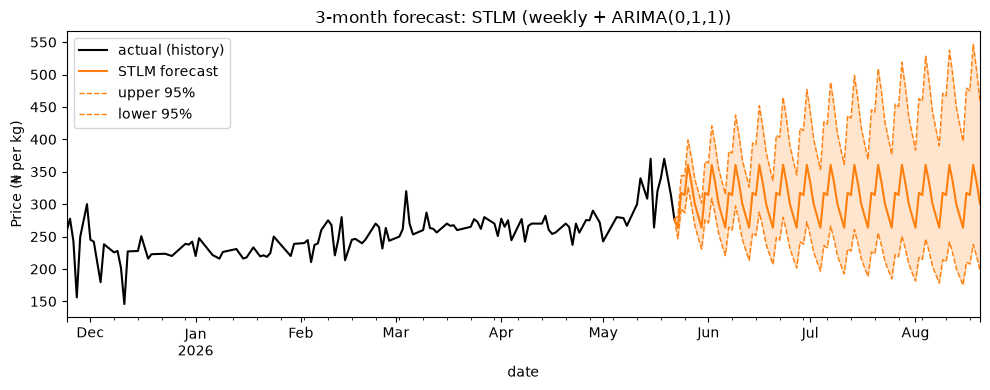

In [14]:
from statsmodels.tsa.forecasting.stl import STLForecast
from statsmodels.tsa.arima.model import ARIMA

HD = 90

def _frame(pred):
    ci = np.exp(pred.conf_int())
    return pd.DataFrame({"forecast": np.exp(pred.predicted_mean),
                         "lower_95": ci.iloc[:, 0], "upper_95": ci.iloc[:, 1]})

def fc_stlm(tr, h=HD):
    res = STLForecast(tr, ARIMA, model_kwargs=dict(order=(0,1,1)),
                      period=7, robust=True).fit()
    return _frame(res.get_prediction(start=len(tr), end=len(tr) + h - 1))

def fc_arima(tr, h=HD):
    return _frame(SARIMAX(tr, order=(0,1,1)).fit(disp=False).get_forecast(h))

def fc_naive(tr, h=HD):
    idx = pd.date_range(tr.index[-1] + pd.Timedelta(days=1), periods=h, freq="D")
    return pd.DataFrame({"forecast": np.exp(tr.iloc[-1])}, index=idx)

def anchor(s, last_date, last_val):
    return pd.concat([pd.Series([last_val], index=[last_date]), s])

def plot_fc(hist, fc, title, test=None, extra=None):
    last_date, last_val = hist.index[-1], hist.iloc[-1]
    fig, ax = plt.subplots(figsize=(10, 4))
    hist.plot(ax=ax, color="gray" if test is not None else "black", label="actual (history)")
    if test is not None:
        pd.concat([hist.iloc[[-1]], test]).plot(ax=ax, color="black", label="actual (test)")
    f, lo, hi = (anchor(fc[c], last_date, last_val) for c in ["forecast","lower_95","upper_95"])
    f.plot(ax=ax, color="C1", label="STLM forecast")
    hi.plot(ax=ax, color="C1", ls="--", lw=1, label="upper 95%")
    lo.plot(ax=ax, color="C1", ls="--", lw=1, label="lower 95%")
    ax.fill_between(f.index, lo, hi, color="C1", alpha=0.2)
    if extra is not None:
        anchor(extra["forecast"], last_date, last_val).plot(ax=ax, color="C0", ls=":", label="ARIMA(0,1,1)")
    ax.set_title(title); ax.set_ylabel("Price (₦ per kg)"); ax.margins(x=0.02)
    ax.legend(); plt.tight_layout(); plt.show()

# ---------- 1) Test: hold out the last 90 days ----------
train, test = lyd.iloc[:-HD], lyd.iloc[-HD:]
act = np.exp(test)
res = {}
for name, fn in {"naive": fc_naive, "ARIMA(0,1,1)": fc_arima, "STLM weekly": fc_stlm}.items():
    f = fn(train)
    ape = (f["forecast"] - act).abs() / act * 100
    row = {"MAPE_%": ape.mean(), "bias_%": ((f["forecast"] - act) / act * 100).mean()}
    if "lower_95" in f:
        row["inside_95%_band"] = ((act >= f["lower_95"]) & (act <= f["upper_95"])).mean() * 100
    res[name] = row
print(pd.DataFrame(res).T.round(2))

t_st, t_ar = fc_stlm(train), fc_arima(train)
plot_fc(np.exp(train).iloc[-120:], t_st, "Test: last 90 days, STLM vs actual",
        test=act, extra=t_ar)

# ---------- 2) Final: next 90 days ----------
fut = fc_stlm(lyd)
print(fut.iloc[[0, 29, 59, 89]].round(2))      # day 1, 30, 60, 90
plot_fc(np.exp(lyd).iloc[-180:], fut, "3-month forecast: STLM (weekly + ARIMA(0,1,1))")

In [21]:
from statsmodels.tsa.seasonal import STL

# 1) Is there a real weekly pattern?
r = STL(lyd, period=7, robust=True).fit()
strength = max(0, 1 - r.resid.var() / (r.seasonal + r.resid).var())
print(f"weekly seasonal strength: {strength:.2f}  (below ~0.3 = weak)")
print((np.exp(r.seasonal.groupby(r.seasonal.index.dayofweek).mean()) - 1).mul(100).round(1)
      .rename(lambda i: ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"][i]))

# 2) Clean one-day outliers (replace with 7-day rolling median)
med = lyd.rolling(7, center=True, min_periods=1).median()
bad = (lyd - med).abs() > 0.25
print("outlier days replaced:", int(bad.sum()))
lyd_c = lyd.where(~bad, med)

# 3) Rolling backtest at the 3-month horizon, raw vs cleaned
HF, MIN_D, STEP_D = 90, 730, 30
def run(series):
    ape = {"naive": [], "ARIMA(0,1,1)": [], "STLM weekly": []}
    fns = {"naive": fc_naive, "ARIMA(0,1,1)": fc_arima, "STLM weekly": fc_stlm}
    for t in range(MIN_D, len(series) - HF + 1, STEP_D):
        tr, te = series.iloc[:t], series.iloc[t:t+HF]
        a = np.exp(te)                       # score against the same data
        for k, fn in fns.items():
            f = fn(tr, HF)["forecast"].values
            ape[k].append((np.abs(f - a.values) / a.values * 100).mean())
    return pd.Series({k: np.mean(v) for k, v in ape.items()}), len(ape["naive"])

raw, n = run(lyd)
print(f"origins: {n}")
print(pd.DataFrame({"raw MAPE %": raw, "cleaned MAPE %": run(lyd_c)[0]}).round(2))

weekly seasonal strength: 0.34  (below ~0.3 = weak)
date
Mon    0.2
Tue    1.0
Wed    0.2
Thu   -1.8
Fri   -0.5
Sat    0.4
Sun    0.5
Name: season, dtype: float64
outlier days replaced: 5
origins: 20
              raw MAPE %  cleaned MAPE %
naive              12.98           12.43
ARIMA(0,1,1)       12.69           12.31
STLM weekly        13.24           12.85


                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1          0.5729      0.136      4.210      0.000       0.306       0.840
ma.S.L12       0.4269      0.242      1.764      0.078      -0.047       0.901
sigma2         0.0117      0.004      3.163      0.002       0.004       0.019
seasonal MA p-value: 0.078  (above 0.05 = not significant)
AIC -63.49 | BIC -58.07

rolling origins: 20
                         overall   h=1    h=2    h=3
ARIMA(0,1,1)               13.69  7.70  14.45  18.91
naive                      14.95  8.56  15.60  20.68
SARIMA(0,1,1)(0,0,1,12)    16.08  9.22  16.58  22.42

holdout: Aug 2026 to Oct 2026
                         MAPE_%  bias_%  actuals_inside_band
naive                     14.40  -14.40                  NaN
ARIMA(0,1,1)              14.57  -14.57                  3.0
SARIMA(0,1,1)(0,0,1,12)   15.51  -15.51                  3.0
            ac

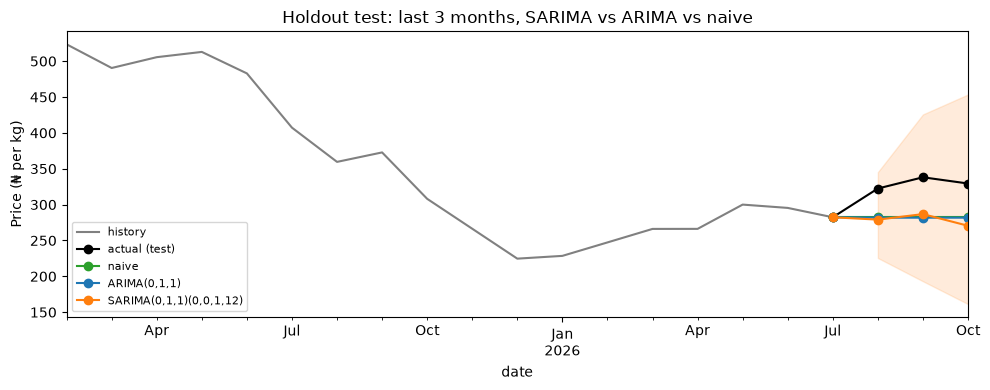

In [23]:
Hm = 3
spec_sarima = ((0,1,1), (0,0,1,12))
specs = {"naive": None,
         "ARIMA(0,1,1)": ((0,1,1), (0,0,0,0)),
         "SARIMA(0,1,1)(0,0,1,12)": spec_sarima}
if "auto_order" in globals():                       # added if you ran the auto cell
    specs[f"auto {auto_order}x{auto_sorder}"] = (auto_order, auto_sorder)

def fcast(tr, sp, h=Hm):
    if sp is None:
        idx = pd.date_range(tr.index[-1], periods=h + 1, freq="MS")[1:]
        return pd.Series(np.exp(tr.iloc[-1]), index=idx), None
    r = SARIMAX(tr, order=sp[0], seasonal_order=sp[1]).fit(disp=False)
    g = r.get_forecast(h)
    return np.exp(g.predicted_mean), np.exp(g.conf_int())

# ---- 1) Coefficients: is the seasonal term doing anything? ----
res = SARIMAX(lm, order=spec_sarima[0], seasonal_order=spec_sarima[1]).fit(disp=False)
print(res.summary().tables[1])
print(f"seasonal MA p-value: {res.pvalues['ma.S.L12']:.3f}  (above 0.05 = not significant)")
print(f"AIC {res.aic:.2f} | BIC {res.bic:.2f}")

# ---- 2) Rolling backtest, overall and by horizon ----
ape = {k: [] for k in specs}
for t in range(24, len(lm) - Hm + 1):
    tr, te = lm.iloc[:t], lm.iloc[t:t+Hm]
    a = np.exp(te.values)
    for k, sp in specs.items():
        f, _ = fcast(tr, sp)
        ape[k].append(np.abs(f.values - a) / a * 100)
print(f"\nrolling origins: {len(ape['naive'])}")
overall = pd.Series({k: np.mean(v) for k, v in ape.items()}).round(2)
by_h = pd.DataFrame({k: np.mean(v, axis=0) for k, v in ape.items()},
                    index=["h=1", "h=2", "h=3"]).T.round(2)
print(pd.concat([overall.rename("overall"), by_h], axis=1).sort_values("overall"))

# ---- 3) Holdout test: forecast the last 3 months from earlier data ----
train, test = lm.iloc[:-Hm], lm.iloc[-Hm:]
act = np.exp(test)
print(f"\nholdout: {test.index[0]:%b %Y} to {test.index[-1]:%b %Y}")
rows, fcs = {}, {}
for k, sp in specs.items():
    f, ci = fcast(train, sp)
    err = (f.values - act.values) / act.values * 100
    row = {"MAPE_%": np.abs(err).mean(), "bias_%": err.mean()}
    if ci is not None:
        row["actuals_inside_band"] = int(((act.values >= ci.iloc[:, 0].values) &
                                          (act.values <= ci.iloc[:, 1].values)).sum())
    rows[k], fcs[k] = row, (f, ci)
print(pd.DataFrame(rows).T.round(2))
print(pd.DataFrame({"actual": act.round(1), **{k: v[0].round(1) for k, v in fcs.items()}}))

fig, ax = plt.subplots(figsize=(10, 4))
hist = np.exp(train).iloc[-18:]
hist.plot(ax=ax, color="gray", label="history")
pd.concat([hist.iloc[[-1]], act]).plot(ax=ax, color="black", marker="o", label="actual (test)")
for (k, (f, ci)), c in zip(fcs.items(), ["C2", "C0", "C1", "C3"]):
    pd.concat([hist.iloc[[-1]], f]).plot(ax=ax, color=c, marker="o", label=k)
sf, sci = fcs["SARIMA(0,1,1)(0,0,1,12)"]
ax.fill_between(sf.index, sci.iloc[:, 0], sci.iloc[:, 1], color="C1", alpha=0.15)
ax.set_title("Holdout test: last 3 months, SARIMA vs ARIMA vs naive")
ax.set_ylabel("Price (₦ per kg)"); ax.margins(x=0.05)
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

46 2023-01-01 to 2026-10-01
origins: 20
naive                      14.95
ARIMA(0,1,1)               13.69
SARIMA(0,1,1)(0,0,1,12)    16.08
dtype: float64
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1          0.5729      0.136      4.210      0.000       0.306       0.840
ma.S.L12       0.4269      0.242      1.764      0.078      -0.047       0.901
sigma2         0.0117      0.004      3.163      0.002       0.004       0.019
            forecast  lower_95  upper_95
2026-11-01    319.16    258.06    394.72
2026-12-01    299.32    201.43    444.78
2027-01-01    308.55    183.76    518.08


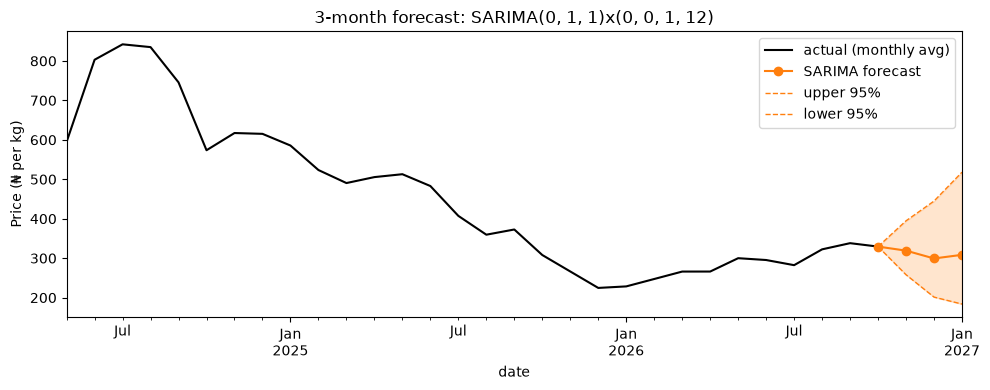

In [22]:
# Monthly series built from the cleaned-up daily data
pm = np.exp(lyd).resample("MS").mean()
lm = np.log(pm)
print(len(lm), lm.index[0].date(), "to", lm.index[-1].date())

order, sorder = (0,1,1), (0,0,1,12)
Hm = 3

# 1) Rolling backtest: SARIMA vs ARIMA vs naive (3-month horizon)
specs = {"naive": None,
         "ARIMA(0,1,1)": ((0,1,1), (0,0,0,0)),
         "SARIMA(0,1,1)(0,0,1,12)": (order, sorder)}
ape = {k: [] for k in specs}
for t in range(24, len(lm) - Hm + 1):
    tr, te = lm.iloc[:t], lm.iloc[t:t+Hm]
    a = np.exp(te.values)
    for k, sp in specs.items():
        f = np.repeat(tr.iloc[-1], Hm) if sp is None else \
            SARIMAX(tr, order=sp[0], seasonal_order=sp[1]).fit(disp=False).forecast(Hm).values
        ape[k].append(np.abs(np.exp(f) - a) / a * 100)
print(f"origins: {len(ape['naive'])}")
print(pd.Series({k: np.mean(v) for k, v in ape.items()}).round(2))

# 2) Fit on all data, forecast 3 months with anchored band
res = SARIMAX(lm, order=order, seasonal_order=sorder).fit(disp=False)
print(res.summary().tables[1])
fc = res.get_forecast(Hm)
ci = np.exp(fc.conf_int())
future = pd.DataFrame({"forecast": np.exp(fc.predicted_mean),
                       "lower_95": ci.iloc[:, 0], "upper_95": ci.iloc[:, 1]})
print(future.round(2))

hist = pm.iloc[-30:]
last_date, last_val = hist.index[-1], hist.iloc[-1]
anchor = lambda s: pd.concat([pd.Series([last_val], index=[last_date]), s])
f, lo, hi = (anchor(future[c]) for c in ["forecast", "lower_95", "upper_95"])

fig, ax = plt.subplots(figsize=(10, 4))
hist.plot(ax=ax, color="black", label="actual (monthly avg)")
f.plot(ax=ax, color="C1", marker="o", label="SARIMA forecast")
hi.plot(ax=ax, color="C1", ls="--", lw=1, label="upper 95%")
lo.plot(ax=ax, color="C1", ls="--", lw=1, label="lower 95%")
ax.fill_between(f.index, lo, hi, color="C1", alpha=0.2)
ax.set_title(f"3-month forecast: SARIMA{order}x{sorder}")
ax.set_ylabel("Price (₦ per kg)"); ax.margins(x=0.05)
ax.legend(); plt.tight_layout(); plt.show()

In [25]:
import itertools

rows = []
for p, q, P, Q in itertools.product([0,1,2], [0,1,2], [0,1], [0,1]):
    try:
        r = SARIMAX(lm, order=(p,1,q), seasonal_order=(P,0,Q,12)).fit(disp=False)
        rows.append({"order": (p,1,q), "sorder": (P,0,Q,12), "AIC": r.aic, "BIC": r.bic})
    except Exception:
        pass

grid = pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)
print(grid.head(8).round(2))

auto_order, auto_sorder = grid.loc[0, "order"], grid.loc[0, "sorder"]
print("auto pick (by AIC):", auto_order, auto_sorder)

# Judge the top 3 by backtest, not AIC
specs = {"naive": None, "ARIMA(0,1,1)": ((0,1,1), (0,0,0,0))}
for i in range(3):
    specs[f"#{i+1} {grid.loc[i,'order']}x{grid.loc[i,'sorder']}"] = (grid.loc[i,"order"], grid.loc[i,"sorder"])

Hm = 3
ape = {k: [] for k in specs}
for t in range(24, len(lm) - Hm + 1):
    tr, te = lm.iloc[:t], lm.iloc[t:t+Hm]
    a = np.exp(te.values)
    for k, sp in specs.items():
        f = np.repeat(tr.iloc[-1], Hm) if sp is None else \
            SARIMAX(tr, order=sp[0], seasonal_order=sp[1]).fit(disp=False).forecast(Hm).values
        ape[k].append(np.abs(np.exp(f) - a) / a * 100)
print(f"origins: {len(ape['naive'])}")
print(pd.Series({k: np.mean(v) for k, v in ape.items()}).sort_values().round(2))

       order         sorder    AIC    BIC
0  (0, 1, 1)  (1, 0, 0, 12) -63.54 -58.12
1  (0, 1, 1)  (0, 0, 1, 12) -63.49 -58.07
2  (0, 1, 1)  (1, 0, 1, 12) -61.60 -54.37
3  (0, 1, 2)  (1, 0, 0, 12) -61.54 -54.32
4  (1, 1, 1)  (1, 0, 0, 12) -61.54 -54.32
5  (0, 1, 2)  (0, 0, 1, 12) -61.49 -54.26
6  (1, 1, 1)  (0, 0, 1, 12) -61.49 -54.26
7  (2, 1, 0)  (0, 0, 1, 12) -61.34 -54.12
auto pick (by AIC): (0, 1, 1) (1, 0, 0, 12)
origins: 20
ARIMA(0,1,1)                  13.69
naive                         14.95
#2 (0, 1, 1)x(0, 0, 1, 12)    16.08
#1 (0, 1, 1)x(1, 0, 0, 12)    17.94
#3 (0, 1, 1)x(1, 0, 1, 12)    21.00
dtype: float64


DAILY   peak 890 on 08 Jul 2024 | low 146 on 11 Dec 2025 | drop 84% | span 17 months
MONTHLY peak 842 in Jul 2024 | low 187 in Feb 2023 | drop 78% | last 329 (Oct 2026)
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1          0.5126      0.134      3.819      0.000       0.250       0.776
sigma2         0.0139      0.004      3.924      0.000       0.007       0.021
Ljung-Box p (12 lags): 0.420  (above 0.05 = no leftover autocorrelation)

rolling origins: 20
               h=1    h=2    h=3  overall
naive         8.56  15.60  20.68    14.95
ARIMA(0,1,1)  7.70  14.45  18.91    13.69

             forecast  lower_95  upper_95
2026-11-01    326.87    259.34    411.97
2026-12-01    326.87    214.85    497.28
2027-01-01    326.87    189.26    564.52


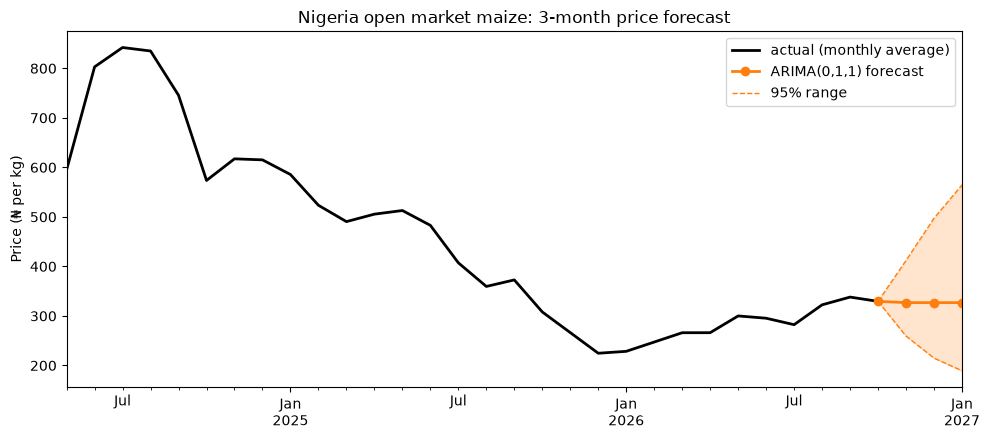

In [26]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# ---- 1) Facts for the post (daily and monthly) ----
pk, lo_ = yd.idxmax(), yd.idxmin()
print(f"DAILY   peak {yd.max():.0f} on {pk:%d %b %Y} | low {yd.min():.0f} on {lo_:%d %b %Y} "
      f"| drop {(1 - yd.min()/yd.max())*100:.0f}% | span {(lo_ - pk).days/30.4:.0f} months")
pkm, lom = pm.idxmax(), pm.idxmin()
print(f"MONTHLY peak {pm.max():.0f} in {pkm:%b %Y} | low {pm.min():.0f} in {lom:%b %Y} "
      f"| drop {(1 - pm.min()/pm.max())*100:.0f}% | last {pm.iloc[-1]:.0f} ({pm.index[-1]:%b %Y})")

# ---- 2) Final model + residual checks ----
Hm = 3
final = SARIMAX(lm, order=(0,1,1)).fit(disp=False)
print(final.summary().tables[1])
lb = acorr_ljungbox(final.resid[1:], lags=[12], return_df=True)["lb_pvalue"].iloc[0]
print(f"Ljung-Box p (12 lags): {lb:.3f}  (above 0.05 = no leftover autocorrelation)")

# ---- 3) Accuracy by horizon: ARIMA vs naive, rolling origins ----
ape = {"naive": [], "ARIMA(0,1,1)": []}
for t in range(24, len(lm) - Hm + 1):
    tr, te = lm.iloc[:t], lm.iloc[t:t+Hm]
    a = np.exp(te.values)
    f_n = np.repeat(tr.iloc[-1], Hm)
    f_a = SARIMAX(tr, order=(0,1,1)).fit(disp=False).forecast(Hm).values
    ape["naive"].append(np.abs(np.exp(f_n) - a) / a * 100)
    ape["ARIMA(0,1,1)"].append(np.abs(np.exp(f_a) - a) / a * 100)
acc = pd.DataFrame({k: np.mean(v, axis=0) for k, v in ape.items()},
                   index=["h=1", "h=2", "h=3"]).T
acc["overall"] = acc.mean(axis=1)
print(f"\nrolling origins: {len(ape['naive'])}")
print(acc.round(2))

# ---- 4) Final 3-month forecast ----
fc = final.get_forecast(Hm)
ci = np.exp(fc.conf_int())
future = pd.DataFrame({"forecast": np.exp(fc.predicted_mean),
                       "lower_95": ci.iloc[:, 0], "upper_95": ci.iloc[:, 1]})
print("\n", future.round(2))

hist = pm.iloc[-30:]
last_date, last_val = hist.index[-1], hist.iloc[-1]
anchor = lambda s: pd.concat([pd.Series([last_val], index=[last_date]), s])
f, lo, hi = (anchor(future[c]) for c in ["forecast", "lower_95", "upper_95"])

fig, ax = plt.subplots(figsize=(10, 4.5))
hist.plot(ax=ax, color="black", lw=2, label="actual (monthly average)")
f.plot(ax=ax, color="C1", marker="o", lw=2, label="ARIMA(0,1,1) forecast")
hi.plot(ax=ax, color="C1", ls="--", lw=1, label="95% range")
lo.plot(ax=ax, color="C1", ls="--", lw=1)
ax.fill_between(f.index, lo, hi, color="C1", alpha=0.2)
ax.set_title("Nigeria open market maize: 3-month price forecast")
ax.set_ylabel("Price (₦ per kg)"); ax.set_xlabel("")
ax.margins(x=0.05); ax.legend(); plt.tight_layout()
plt.savefig("maize_forecast.png", dpi=200); plt.show()